In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('hotel_bookings.csv')
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,no,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,7/1/2015
1,Resort Hotel,no,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,7/1/2015
2,Resort Hotel,no,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,7/2/2015
3,Resort Hotel,no,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,7/2/2015
4,Resort Hotel,no,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,7/3/2015


In [2]:
df.shape
df.info()
df.describe()
df['is_canceled'].value_counts()
df['hotel'].value_counts()

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  str    
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

hotel
City Hotel      79330
Resort Hotel    40060
Name: count, dtype: int64

In [5]:
df = df.replace('NULL', np.nan)      # dans ce fichier, "NULL" est écrit en texte
df.isna().sum()                      # valeurs manquantes

df = df.drop(columns=['company'])    # 94 % de vides
df['children'] = df['children'].fillna(0)
df['country'] = df['country'].fillna('Inconnu')

df.duplicated().sum()                # nombre de doublons
df = df.drop_duplicates()

# réservations sans aucun client
vides = (df['adults'] + df['children'] + df['babies']) == 0
df = df[~vides]

# colonne cible en 0/1 (le fichier contient "yes"/"no")
df['annule'] = (df['is_canceled'] == 'yes').astype(int)

KeyError: "['company'] not found in axis"

In [6]:
df = pd.read_csv('hotel_bookings.csv')

In [7]:
df = df.replace('NULL', np.nan)
df = df.drop(columns=['company'], errors='ignore')
df['children'] = df['children'].fillna(0)
df['country'] = df['country'].fillna('Inconnu')

In [8]:
df.columns

Index(['hotel', 'is_canceled', 'lead_time', 'arrival_date_year',
       'arrival_date_month', 'arrival_date_week_number',
       'arrival_date_day_of_month', 'stays_in_weekend_nights',
       'stays_in_week_nights', 'adults', 'children', 'babies', 'meal',
       'country', 'market_segment', 'distribution_channel',
       'is_repeated_guest', 'previous_cancellations',
       'previous_bookings_not_canceled', 'reserved_room_type',
       'assigned_room_type', 'booking_changes', 'deposit_type', 'agent',
       'days_in_waiting_list', 'customer_type', 'adr',
       'required_car_parking_spaces', 'total_of_special_requests',
       'reservation_status', 'reservation_status_date'],
      dtype='str')

In [9]:
df['children'] = df['children'].fillna(0)
df['country'] = df['country'].fillna('Inconnu')

df.duplicated().sum()          # nombre de doublons
df = df.drop_duplicates()

# réservations sans aucun client
vides = (df['adults'] + df['children'] + df['babies']) == 0
df = df[~vides]

# colonne cible en 0/1
df['annule'] = (df['is_canceled'] == 'yes').astype(int)

df.shape

(87223, 32)

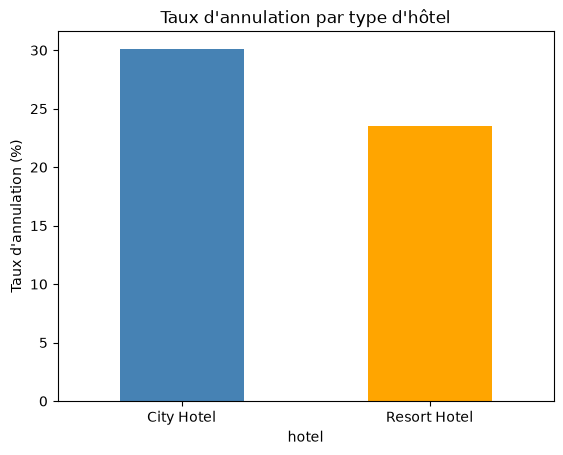

In [10]:
# taux global
df['annule'].mean() * 100

# par type d'hôtel
df.groupby('hotel')['annule'].mean() * 100

# graphique
(df.groupby('hotel')['annule'].mean() * 100).plot(kind='bar', color=['steelblue', 'orange'])
plt.ylabel("Taux d'annulation (%)")
plt.title("Taux d'annulation par type d'hôtel")
plt.xticks(rotation=0)
plt.show()

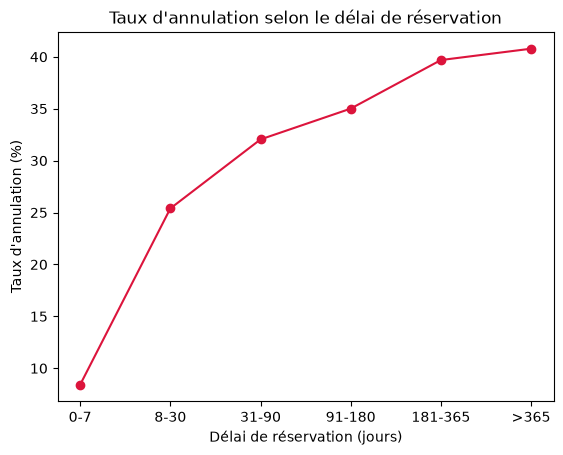

np.float64(0.1844818316081496)

In [11]:
# délai moyen selon annulation (0 = maintenue, 1 = annulée)
df.groupby('annule')['lead_time'].mean()

# tranches de délai
df['tranche'] = pd.cut(df['lead_time'],
                       bins=[-1, 7, 30, 90, 180, 365, 1000],
                       labels=['0-7', '8-30', '31-90', '91-180', '181-365', '>365'])

taux = df.groupby('tranche', observed=True)['annule'].mean() * 100
taux

# graphique
taux.plot(marker='o', color='crimson')
plt.xlabel("Délai de réservation (jours)")
plt.ylabel("Taux d'annulation (%)")
plt.title("Taux d'annulation selon le délai de réservation")
plt.show()

# corrélation
df['lead_time'].corr(df['annule'])

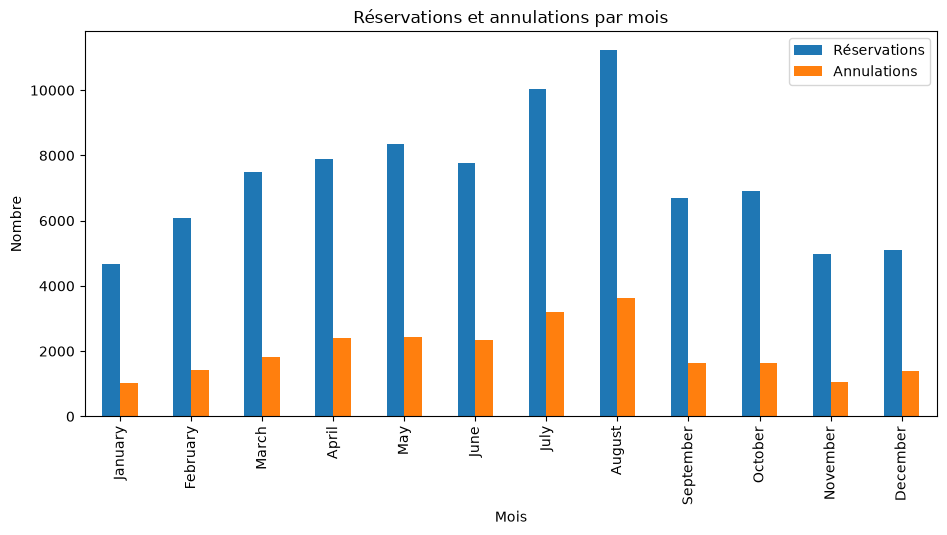

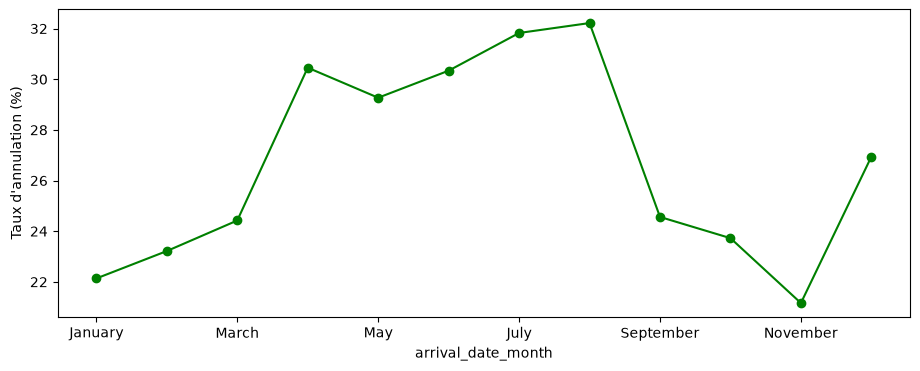

('August', 'August', 'August')

In [12]:
ordre = ['January','February','March','April','May','June','July','August',
         'September','October','November','December']

mois = df.groupby('arrival_date_month')['annule'].agg(['count', 'sum', 'mean']).reindex(ordre)
mois['mean'] = mois['mean'] * 100
mois

# réservations et annulations par mois
mois[['count', 'sum']].plot(kind='bar', figsize=(11, 5))
plt.title("Réservations et annulations par mois")
plt.xlabel("Mois")
plt.ylabel("Nombre")
plt.legend(['Réservations', 'Annulations'])
plt.show()

# taux d'annulation par mois
mois['mean'].plot(marker='o', figsize=(11, 4), color='green')
plt.ylabel("Taux d'annulation (%)")
plt.show()

# mois maximum
mois['count'].idxmax(), mois['sum'].idxmax(), mois['mean'].idxmax()

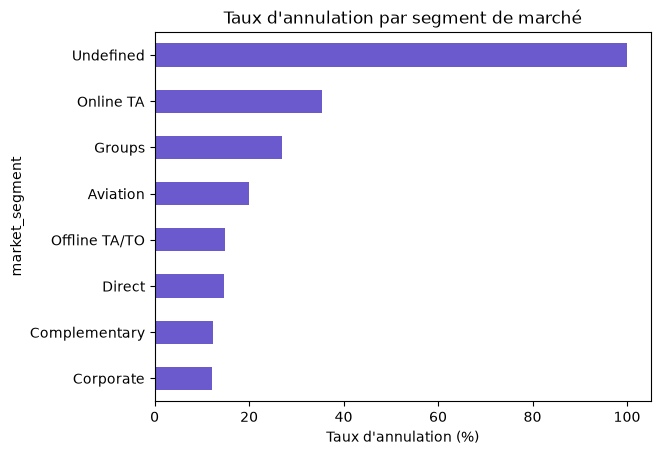

In [13]:
# type de dépôt
df.groupby('deposit_type')['annule'].mean() * 100

# segment de marché
seg = df.groupby('market_segment')['annule'].mean().sort_values(ascending=False) * 100
seg

seg.plot(kind='barh', color='slateblue')
plt.xlabel("Taux d'annulation (%)")
plt.title("Taux d'annulation par segment de marché")
plt.gca().invert_yaxis()
plt.show()

In [14]:
seg = seg.drop('Undefined')

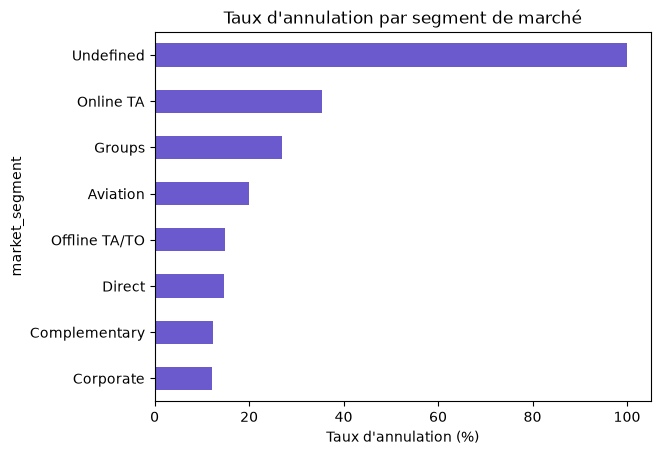

In [15]:
df.groupby('deposit_type')['annule'].mean() * 100

# segment de marché
seg = df.groupby('market_segment')['annule'].mean().sort_values(ascending=False) * 100
seg

seg.plot(kind='barh', color='slateblue')
plt.xlabel("Taux d'annulation (%)")
plt.title("Taux d'annulation par segment de marché")
plt.gca().invert_yaxis()
plt.show()